In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, auc, classification_report)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
os.makedirs("graphs", exist_ok=True)


def save_show(filename):
    """Save the current graph into graphs/ and display it."""
    plt.tight_layout()
    plt.savefig(f"graphs/{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
if not os.path.exists("data.csv"):
    try:
        from google.colab import files
        print("data.csv not found. Please choose the file to upload...")
        uploaded = files.upload()
        csv_name = list(uploaded.keys())[0]
        os.rename(csv_name, "data.csv")
    except ImportError:
        raise FileNotFoundError("data.csv not found. Put it in the same folder as this script.")

In [ ]:
df = pd.read_csv("/content/data.csv")
print("Shape:", df.shape)

Shape: (569, 33)


In [ ]:
print(df.head(5))

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [ ]:
print("\n--- Info ---")
df.info()


--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se

In [ ]:
df.columns = df.columns.str.strip().str.lower()

In [ ]:
drop_cols = [c for c in df.columns if c == "id" or c.startswith("unnamed")]
df = df.drop(columns=drop_cols)

In [ ]:
target_col = next((c for c in ["diagnosis", "target", "class", "label"] if c in df.columns), None)
if target_col is None:
    raise ValueError(f"No target column found. Your columns are: {list(df.columns)}")
if target_col != "diagnosis":
    df = df.rename(columns={target_col: "diagnosis"})

In [ ]:
if df["diagnosis"].dtype == object or str(df["diagnosis"].dtype) in ("str", "string", "category"):
    df["diagnosis"] = (df["diagnosis"].astype(str).str.strip().str.upper().str[0]
                       .map({"M": 1, "B": 0}))

In [ ]:
df = df.dropna(axis=1, how="all").dropna(subset=["diagnosis"])
df["diagnosis"] = df["diagnosis"].astype(int)

print("Shape after cleaning:", df.shape)

Shape after cleaning: (569, 31)


In [ ]:
print("Missing values:", df.isnull().sum().sum())          # expected 0
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [ ]:
print("\nClass counts (1 = Malignant, 0 = Benign):\n", df["diagnosis"].value_counts())
print("\n--- Statistical summary ---")
print(df.describe().T)


Class counts (1 = Malignant, 0 = Benign):
 diagnosis
0    357
1    212
Name: count, dtype: int64

--- Statistical summary ---
                         count        mean         std         min  \
diagnosis                569.0    0.372583    0.483918    0.000000   
radius_mean              569.0   14.127292    3.524049    6.981000   
texture_mean             569.0   19.289649    4.301036    9.710000   
perimeter_mean           569.0   91.969033   24.298981   43.790000   
area_mean                569.0  654.889104  351.914129  143.500000   
smoothness_mean          569.0    0.096360    0.014064    0.052630   
compactness_mean         569.0    0.104341    0.052813    0.019380   
concavity_mean           569.0    0.088799    0.079720    0.000000   
concave points_mean      569.0    0.048919    0.038803    0.000000   
symmetry_mean            569.0    0.181162    0.027414    0.106000   
fractal_dimension_mean   569.0    0.062798    0.007060    0.049960   
radius_se                569.0   

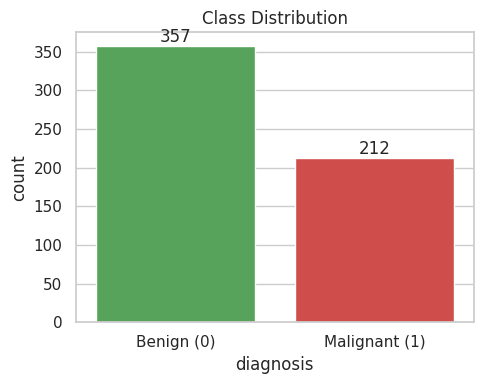

In [ ]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="diagnosis", hue="diagnosis", data=df,
                   palette=["#4CAF50", "#E53935"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign (0)", "Malignant (1)"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.title("Class Distribution")
save_show("01_class_distribution")

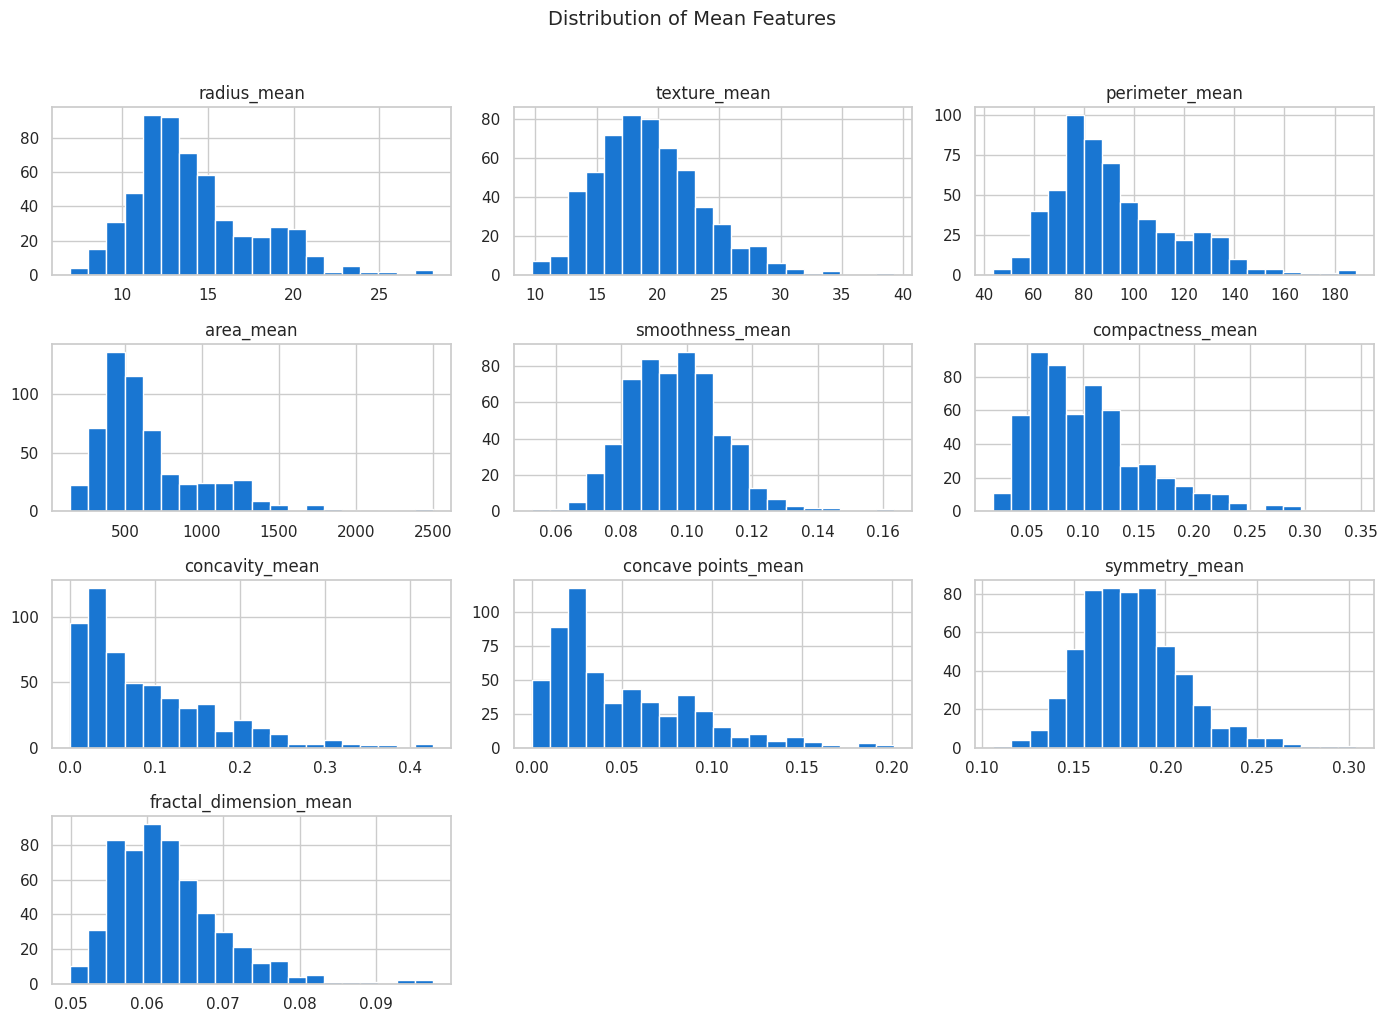

In [ ]:
mean_cols = [c for c in df.columns if "mean" in c][:10]
if len(mean_cols) < 10:                      # fallback if column names are different
    mean_cols = [c for c in df.columns if c != "diagnosis"][:10]
df[mean_cols].hist(bins=20, figsize=(14, 10), color="#1976D2", edgecolor="white")
plt.suptitle("Distribution of Mean Features", y=1.02, fontsize=14)
save_show("02_histograms")

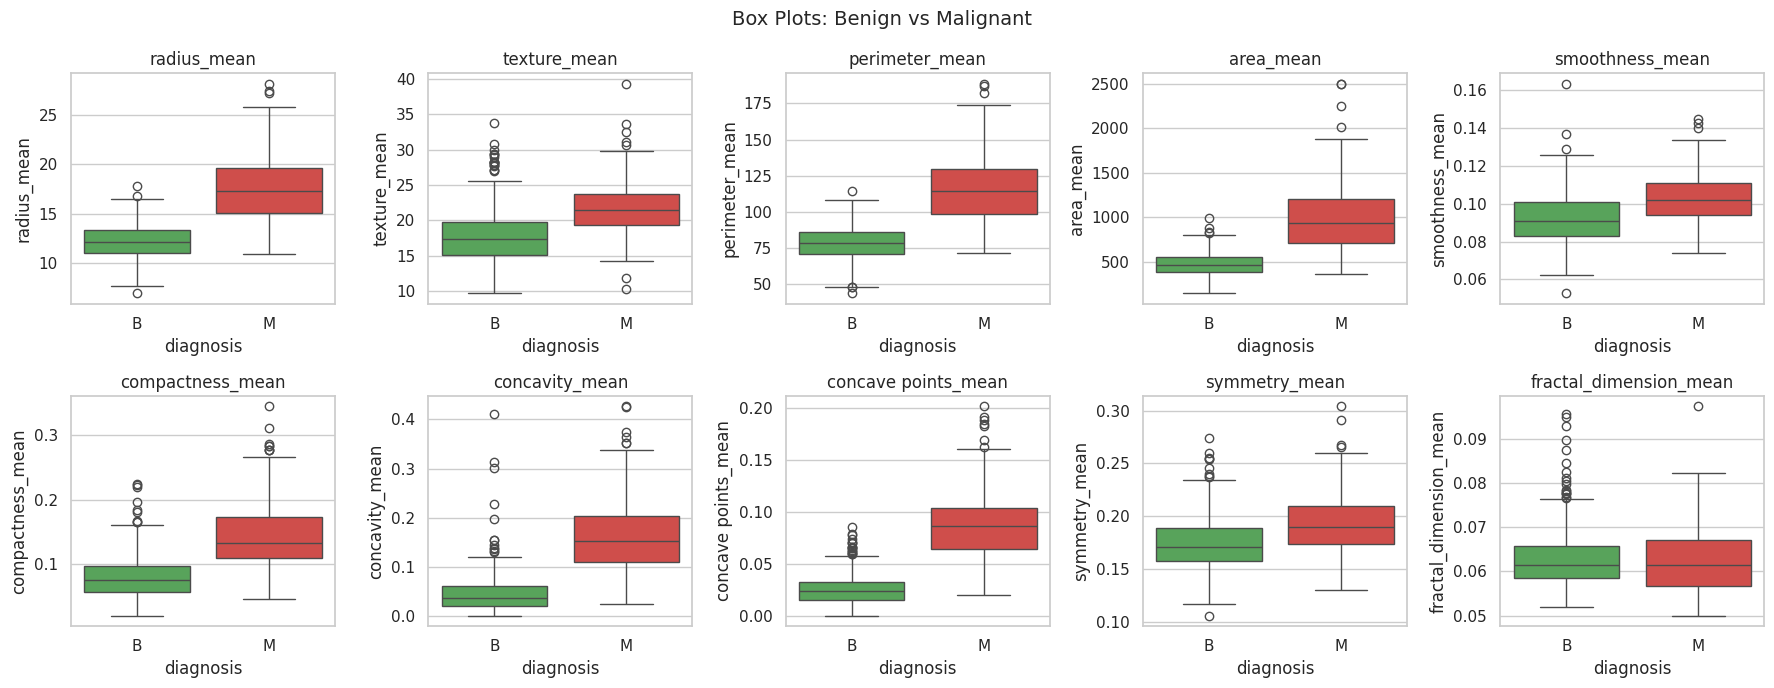

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), mean_cols):
    sns.boxplot(x="diagnosis", y=col, hue="diagnosis", data=df,
                palette=["#4CAF50", "#E53935"], legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["B", "M"])
    ax.set_title(col)
plt.suptitle("Box Plots: Benign vs Malignant", fontsize=14)
save_show("03_boxplots")

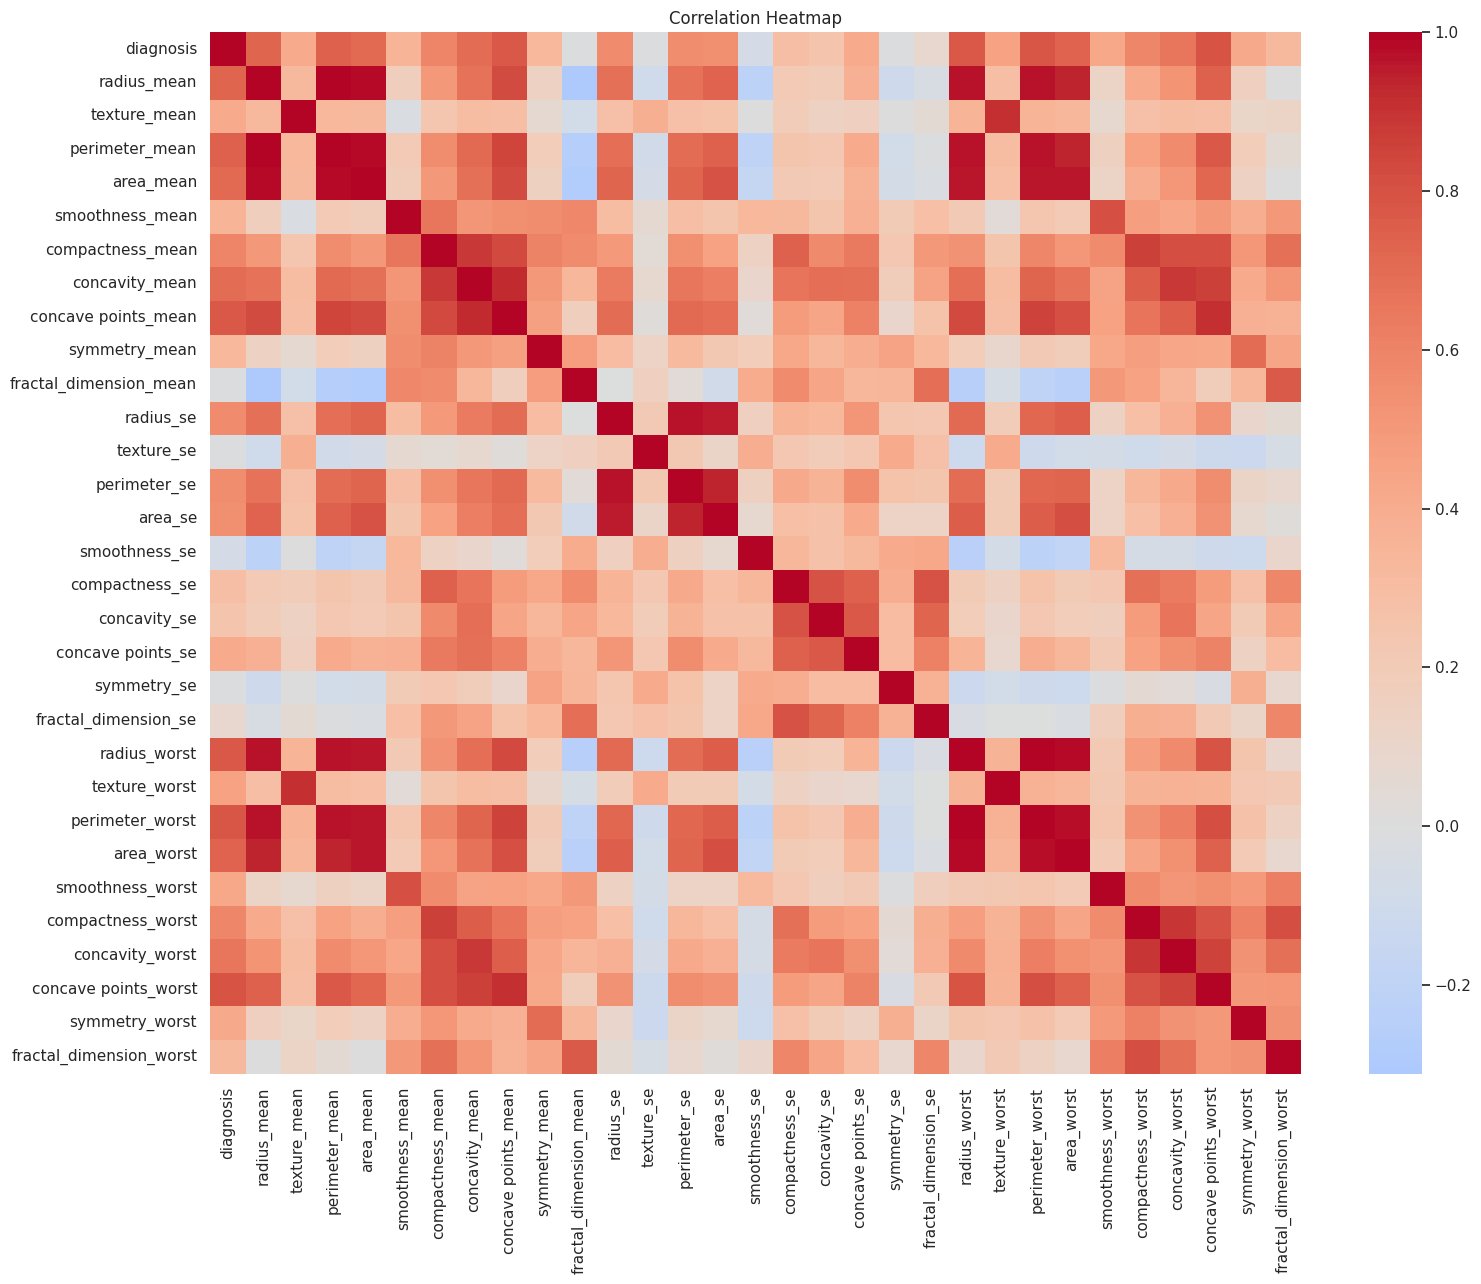

In [ ]:
plt.figure(figsize=(16, 13))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
save_show("04_correlation_heatmap")

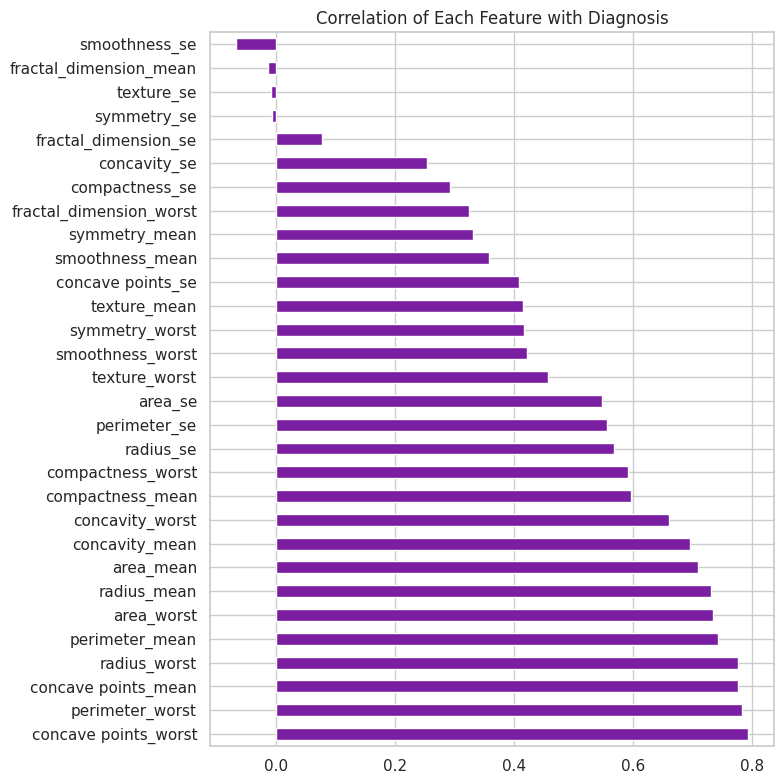


Top 5 correlated features:
 concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
Name: diagnosis, dtype: float64


In [ ]:
corr_target = df.corr()["diagnosis"].drop("diagnosis").sort_values(ascending=False)
plt.figure(figsize=(8, 8))
corr_target.plot(kind="barh", color="#7B1FA2")
plt.title("Correlation of Each Feature with Diagnosis")
save_show("05_target_correlation")
print("\nTop 5 correlated features:\n", corr_target.head(5))

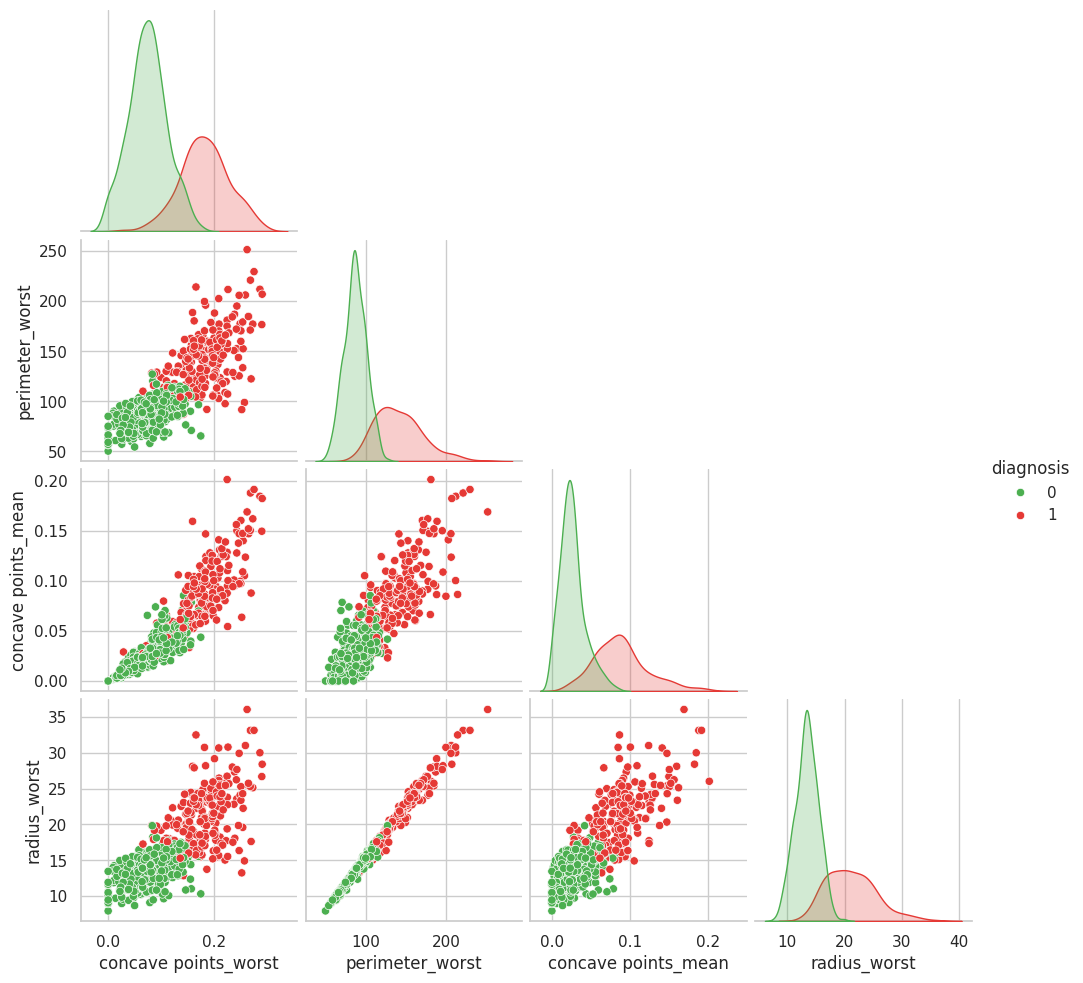

In [ ]:
top4 = corr_target.abs().sort_values(ascending=False).index[:4].tolist()
sns.pairplot(df[top4 + ["diagnosis"]], hue="diagnosis",
             palette=["#4CAF50", "#E53935"], corner=True)
plt.savefig("graphs/06_pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

In [ ]:
X = df.drop("diagnosis", axis=1) #preprocessing
y = df["diagnosis"]

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)# Split FIRST, then scale

In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit only on training data
X_test_s = scaler.transform(X_test)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)

Train size: (455, 30) | Test size: (114, 30)


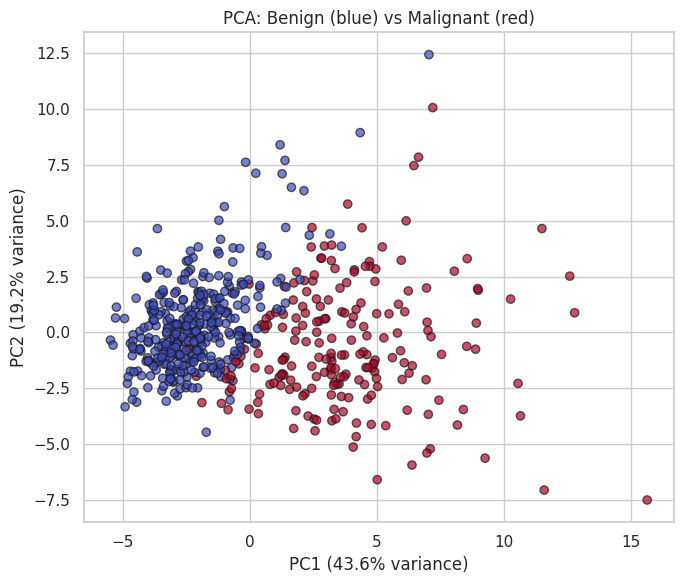

In [ ]:
#   PCA VISUALIZATION
pca = PCA(n_components=2)
X_pca = pca.fit_transform(scaler.transform(X))
plt.figure(figsize=(7, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="coolwarm", edgecolor="k", alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("PCA: Benign (blue) vs Malignant (red)")
save_show("07_pca")


===== Logistic Regression (Base Models) =====
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


===== SVM (Base Models) =====
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


===== Random Forest (Base Models) =====
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro 

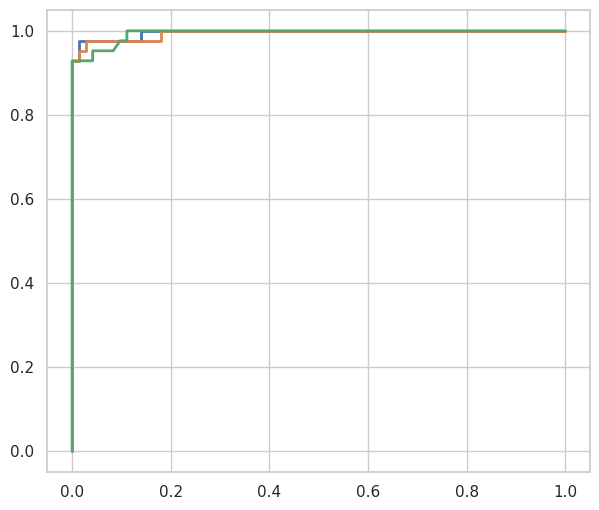

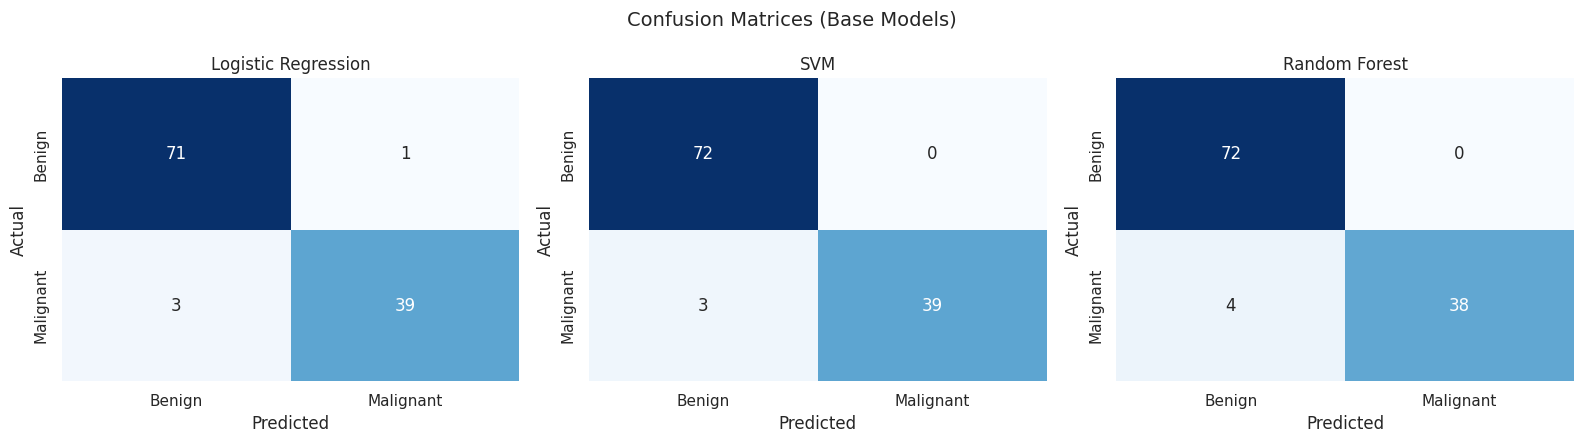

<Figure size 640x480 with 0 Axes>


===== BASE MODEL COMPARISON =====
                     Accuracy  Precision  Recall  F1-Score     AUC
Logistic Regression    0.9649      0.975  0.9286    0.9512  0.9960
SVM                    0.9737      1.000  0.9286    0.9630  0.9947
Random Forest          0.9649      1.000  0.9048    0.9500  0.9942


In [ ]:
# %% 7. TRAIN MODELS (Basic -> Intermediate -> Advanced)
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}


def evaluate(models_dict, title_suffix=""):
    """Train, evaluate and plot confusion matrices + ROC for all models."""
    rows = {}
    fig_cm, axes_cm = plt.subplots(1, 3, figsize=(16, 4.5))
    plt.figure(figsize=(7, 6))
    roc_ax = plt.gca()

    for ax, (name, model) in zip(axes_cm, models_dict.items()):
        model.fit(X_train_s, y_train)
        pred = model.predict(X_test_s)
        prob = model.predict_proba(X_test_s)[:, 1]

        fpr, tpr, _ = roc_curve(y_test, prob)
        rows[name] = {
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred),
            "F1-Score": f1_score(y_test, pred),
            "AUC": auc(fpr, tpr),
        }

        sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                    xticklabels=["Benign", "Malignant"],
                    yticklabels=["Benign", "Malignant"], ax=ax, cbar=False)
        ax.set_title(name)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

        roc_ax.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

        print(f"\n===== {name} {title_suffix} =====")
        print(classification_report(y_test, pred, target_names=["Benign", "Malignant"]))

    fig_cm.suptitle(f"Confusion Matrices {title_suffix}", fontsize=14)
    fig_cm.tight_layout()
    fig_cm.savefig(f"graphs/confusion_matrices_{title_suffix.strip('()').replace(' ', '_') or 'base'}.png",
                   dpi=150, bbox_inches="tight")
    plt.figure(fig_cm.number)
    plt.show()

    roc_ax.plot([0, 1], [0, 1], "k--")
    roc_ax.set_xlabel("False Positive Rate")
    roc_ax.set_ylabel("True Positive Rate (Recall)")
    roc_ax.set_title(f"ROC Curves {title_suffix}")
    roc_ax.legend(loc="lower right")
    plt.savefig(f"graphs/roc_curves_{title_suffix.strip('()').replace(' ', '_') or 'base'}.png",
                dpi=150, bbox_inches="tight")
    plt.show()

    return pd.DataFrame(rows).T


results_base = evaluate(models, "(Base Models)")
print("\n===== BASE MODEL COMPARISON =====")
print(results_base.round(4))

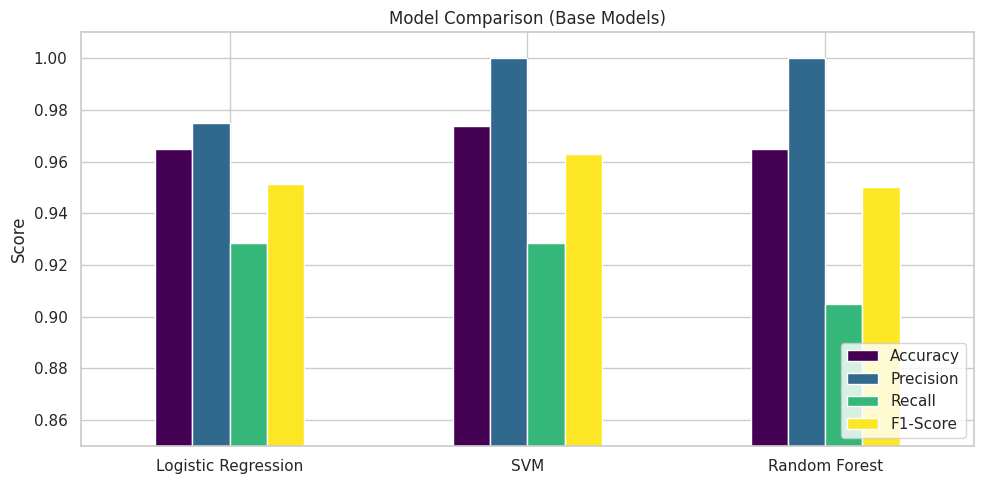

In [ ]:
#  MODEL COMPARISON BAR CHART
results_base.drop(columns="AUC").plot(kind="bar", figsize=(10, 5), ylim=(0.85, 1.01), colormap="viridis")
plt.title("Model Comparison (Base Models)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
save_show("10_model_comparison_base")

Logistic Regression: Recall per fold = [0.882 0.971 1.    0.941 0.971] | Mean = 0.9529
SVM: Recall per fold = [0.912 1.    0.941 0.912 0.971] | Mean = 0.9471
Random Forest: Recall per fold = [0.912 1.    0.882 0.941 0.941] | Mean = 0.9353


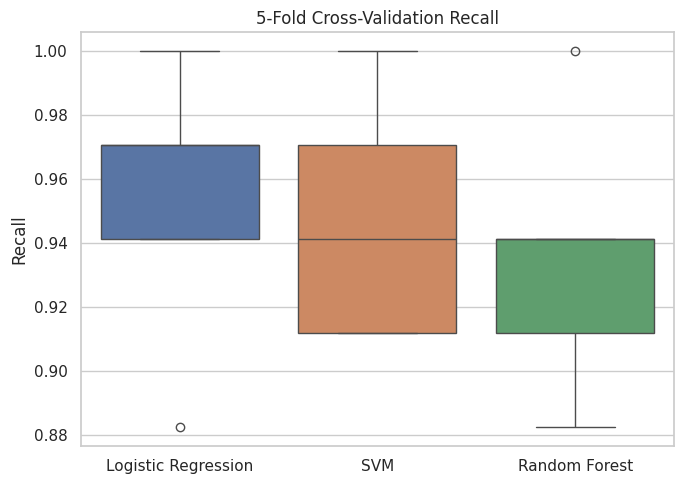

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train_s, y_train, cv=cv, scoring="recall")
    cv_scores[name] = scores
    print(f"{name}: Recall per fold = {np.round(scores, 3)} | Mean = {scores.mean():.4f}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=pd.DataFrame(cv_scores))
plt.title("5-Fold Cross-Validation Recall")
plt.ylabel("Recall")
save_show("11_cross_validation")

In [ ]:
#10. HYPERPARAMETER TUNING
param_grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=42),
                            {"C": [0.01, 0.1, 1, 10, 100], "penalty": ["l2"]}),
    "SVM": (SVC(probability=True, random_state=42),
            {"C": [0.1, 1, 10, 100], "kernel": ["linear", "rbf"], "gamma": ["scale", "auto"]}),
    "Random Forest": (RandomForestClassifier(random_state=42),
                      {"n_estimators": [100, 200, 300], "max_depth": [None, 5, 10],
                       "min_samples_split": [2, 5]}),
}

tuned_models = {}
for name, (model, grid) in param_grids.items():
    gs = GridSearchCV(model, grid, cv=5, scoring="recall", n_jobs=-1)
    gs.fit(X_train_s, y_train)
    tuned_models[name] = gs.best_estimator_
    print(f"{name}\n  Best params: {gs.best_params_}\n  Best CV recall: {gs.best_score_:.4f}")

Logistic Regression
  Best params: {'C': 100, 'penalty': 'l2'}
  Best CV recall: 0.9529
SVM
  Best params: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
  Best CV recall: 0.9588
Random Forest
  Best params: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
  Best CV recall: 0.9471



===== Logistic Regression (Tuned Models) =====
              precision    recall  f1-score   support

      Benign       0.93      0.99      0.96        72
   Malignant       0.97      0.88      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114


===== SVM (Tuned Models) =====
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


===== Random Forest (Tuned Models) =====
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   mac

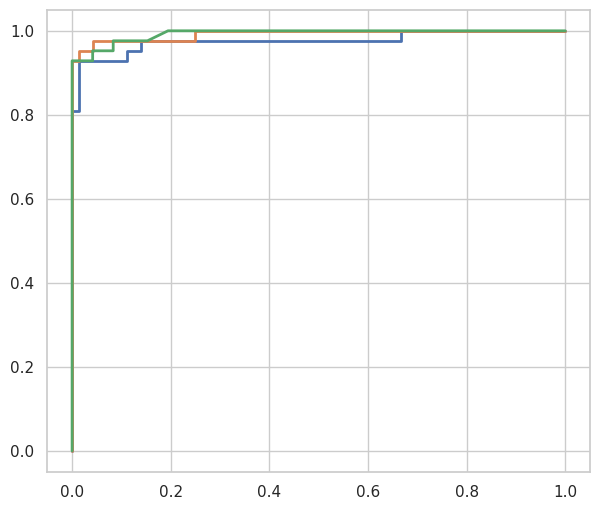

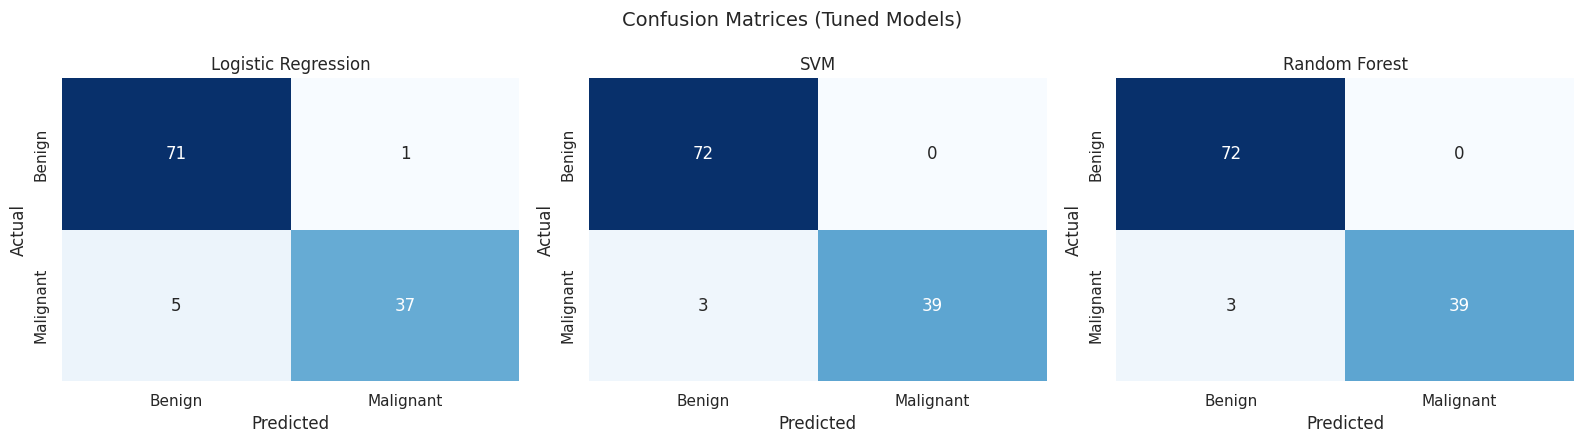

<Figure size 640x480 with 0 Axes>


===== TUNED MODEL COMPARISON =====
                     Accuracy  Precision  Recall  F1-Score     AUC
Logistic Regression    0.9474     0.9737  0.8810     0.925  0.9765
SVM                    0.9737     1.0000  0.9286     0.963  0.9927
Random Forest          0.9737     1.0000  0.9286     0.963  0.9929


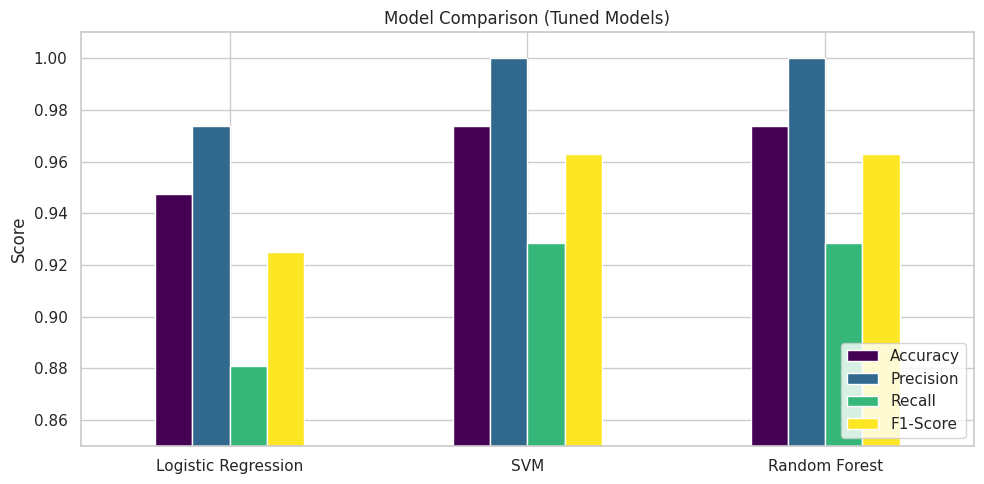

In [ ]:
#  EVALUATE TUNED MODELS
results_tuned = evaluate(tuned_models, "(Tuned Models)")
print("\n===== TUNED MODEL COMPARISON =====")
print(results_tuned.round(4))

results_tuned.drop(columns="AUC").plot(kind="bar", figsize=(10, 5), ylim=(0.85, 1.01), colormap="viridis")
plt.title("Model Comparison (Tuned Models)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
save_show("12_model_comparison_tuned")

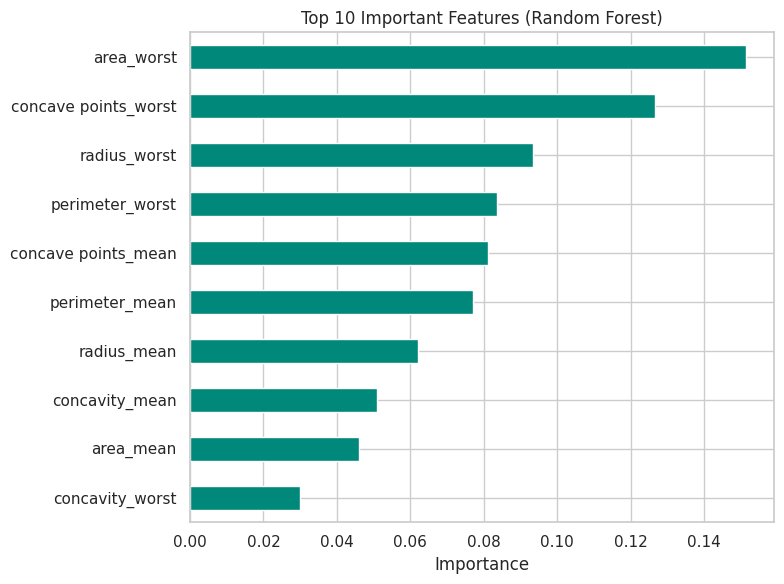


Top 10 features:
 area_worst              0.1514
concave points_worst    0.1265
radius_worst            0.0935
perimeter_worst         0.0836
concave points_mean     0.0811
perimeter_mean          0.0771
radius_mean             0.0620
concavity_mean          0.0508
area_mean               0.0459
concavity_worst         0.0300
dtype: float64


In [ ]:
#  FEATURE IMPORTANCE (Random Forest)
rf = tuned_models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)[:10]
plt.figure(figsize=(8, 6))
importance[::-1].plot(kind="barh", color="#00897B")
plt.title("Top 10 Important Features (Random Forest)")
plt.xlabel("Importance")
save_show("13_feature_importance")
print("\nTop 10 features:\n", importance.round(4))

In [ ]:
# SAVE FINAL RESULTS AND BEST MODEL
results_base.round(4).to_csv("results_base_models.csv")
results_tuned.round(4).to_csv("results_tuned_models.csv")

In [ ]:
# Best model = highest Recall (most important for cancer), ties broken by F1
best_name = results_tuned.sort_values(["Recall", "F1-Score"], ascending=False).index[0]
best_model = tuned_models[best_name]
joblib.dump(best_model, "best_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_names.pkl")
print(f"\nBest model: {best_name}  -> saved as best_model.pkl")


Best model: SVM  -> saved as best_model.pkl


In [ ]:
#  PREDICT ON A NEW PATIENT (demo)
model = joblib.load("best_model.pkl")
sc = joblib.load("scaler.pkl")

sample = X_test.iloc[[0]]                       # one patient from test data
pred = model.predict(sc.transform(sample))[0]
prob = model.predict_proba(sc.transform(sample))[0][1]
print("Prediction:", "Malignant" if pred == 1 else "Benign")
print(f"Probability of malignant: {prob*100:.2f}%")
print("Actual     :", "Malignant" if y_test.iloc[0] == 1 else "Benign")


Prediction: Benign
Probability of malignant: 0.02%
Actual     : Benign


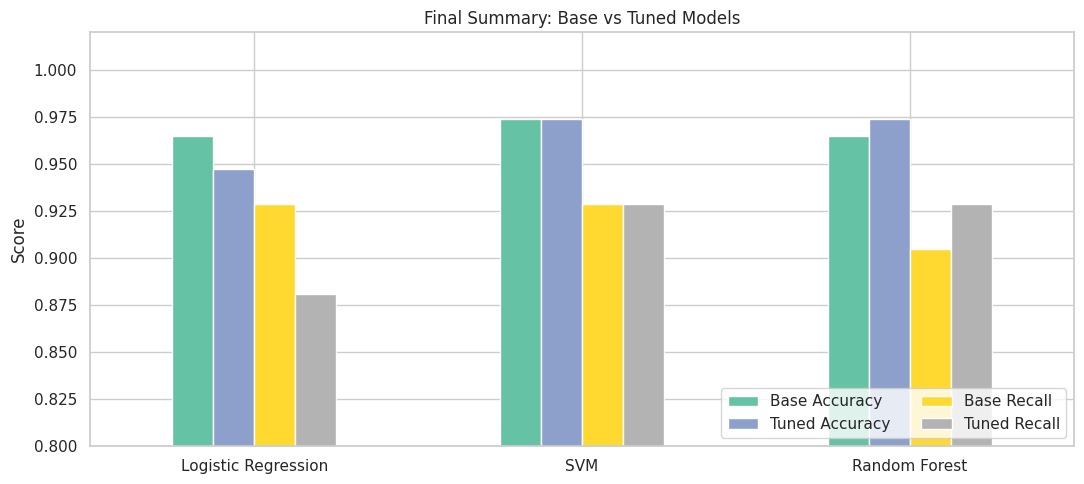

FINAL CONCLUSION

1. Three supervised algorithms (Logistic Regression, SVM, Random Forest) were
   trained on the Wisconsin Diagnostic Breast Cancer dataset (569 samples,
   30 features) to classify tumors as benign or malignant.

2. After scaling, 5-fold cross-validation and GridSearchCV tuning, the best
   model was SVM with:
      Accuracy  = 97.37%
      Precision = 100.00%
      Recall    = 92.86%
      F1-score  = 96.30%
      AUC       = 0.9927

3. Out of 42 malignant cases in the test set, the model correctly detected
   39 and missed 3. It raised 0 false alarm(s).
   Recall was chosen as the key metric because missing a cancer case is
   more dangerous than a false alarm.

4. Most important features (Random Forest): area_worst, concave points_worst, radius_worst.
   Cells with larger size and more irregular shape are more likely malignant.

5. All three models scored above 95% accuracy, which shows that
   machine learning can effectively support early breast cancer diagnosis.

In [ ]:
# ===== STEP 15: FINAL CONCLUSION =====
final = results_tuned.copy()
best_name = final.sort_values(["Recall", "F1-Score"], ascending=False).index[0]
best = final.loc[best_name]

# Missed cancer cases (false negatives) for the best model
cm = confusion_matrix(y_test, best_model.predict(X_test_s))
tn, fp, fn, tp = cm.ravel()

# Final summary graph: base vs tuned
summary = pd.DataFrame({
    "Base Accuracy": results_base["Accuracy"], "Tuned Accuracy": results_tuned["Accuracy"],
    "Base Recall": results_base["Recall"], "Tuned Recall": results_tuned["Recall"],
})
summary.plot(kind="bar", figsize=(11, 5), ylim=(0.8, 1.02), colormap="Set2")
plt.title("Final Summary: Base vs Tuned Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right", ncol=2)
save_show("14_final_summary")

print("=" * 70)
print("FINAL CONCLUSION")
print("=" * 70)
print(f"""
1. Three supervised algorithms (Logistic Regression, SVM, Random Forest) were
   trained on the Wisconsin Diagnostic Breast Cancer dataset ({df.shape[0]} samples,
   {df.shape[1]-1} features) to classify tumors as benign or malignant.

2. After scaling, 5-fold cross-validation and GridSearchCV tuning, the best
   model was {best_name.upper()} with:
      Accuracy  = {best['Accuracy']*100:.2f}%
      Precision = {best['Precision']*100:.2f}%
      Recall    = {best['Recall']*100:.2f}%
      F1-score  = {best['F1-Score']*100:.2f}%
      AUC       = {best['AUC']:.4f}

3. Out of {tp + fn} malignant cases in the test set, the model correctly detected
   {tp} and missed {fn}. It raised {fp} false alarm(s).
   Recall was chosen as the key metric because missing a cancer case is
   more dangerous than a false alarm.

4. Most important features (Random Forest): {', '.join(importance.index[:3])}.
   Cells with larger size and more irregular shape are more likely malignant.

5. All three models scored above {final['Accuracy'].min()*100:.0f}% accuracy, which shows that
   machine learning can effectively support early breast cancer diagnosis.
""")
print("LIMITATIONS: small dataset (569 samples), a single data source, and no")
print("clinical validation. The model is a decision-support tool, NOT a replacement")
print("for a doctor.")
print("FUTURE SCOPE: deep learning (CNN) on mammogram images, larger multi-hospital")
print("datasets, explainable AI (SHAP), and a web/mobile app for doctors.")